# Create and run a local RAG pipeline from scratch

RAG stands for Retrieval Augmented Generation.

The goal of RAG is to take information and pass it to an LLM so it can generate outputs based on that information.

* Retrieval - Find relevant information given a query, e.g. "What are macronutrients and what do they do?" -> retrieves passages of text related to the macronutrients from a nutrition textbook.
* Augmentation - We want to take the relevant information and augment our input (prompt) to an LLM with that relevant information.
* Generation - Take the first two steps and pass them to an LLM for generative outputs.

## Goal

The main goal of RAG is to improve the generation outputs of LLMs.

1. Prevent hallucinations - LLMs are incredibly good at generating good *looking* text, however, this doesn't mean that it's factual.
2. Work with custom data - Many base LLMs are trained with internet-scale data. This means they have a fairly good understanding of language in general. However, it also does mean a lot of their responses can be generic in nature. RAG helps to create specific responses based on specific documents(e.g. your own company's customer support documents.)

## Uses

* Customer support Q&A chat - Treat your existing support documents as a resource and when a customer asks a question, you could have a retrieval system, retrieve relevant documentation snippets and then have an LLM craft those snippets into an answer. Can think of it as "chatbot for your documentation".
* Email chain analysis - Let's say you're a large insurance company and you have chains and chains of emails of customer claims. You could use a RAG pipeline to find relevant information from those emails and then use an LLM to process that information into structured data.
* Company internal documentation chat.
* Textbook Q&A - Let's say you're a nutrition student and you've got a 1200 page textbook read, you could build a RAG pipeline to go through the textbook and find relevant passages to the questions you have.

Common theme here: take your relevant documents to a query and process them with an LLM.

## Why Local?

Privacy, Speed, Cost.

* Privacy - If you have private documentation, maybe you don't want to send that to an API. You want to setup an LLM and run it on your own hardware.
* Speed - Whenever you use an API, you have to send some kind of data across the internet. This takes time. Running locally means we don't have to wait for transfer of data.
* Cost - If you own your hardware, the cost is paid overtime. Don't have to keep paying API fees.
* No vendor lockin - If you run your own software/hardware.

We're going to build NutriChat to "chat with a nutrition textbook".

1. Open a PDF document.
2. Format the text of the PDF textbook ready for an embedding model.
3. Embed all of the chunks of text in the textbook and turn them into numerical representations (embedding) which we can store for later.
4. Build a retrieval system that uses vector search to find relevant chunks of text based on a query.
5. Create a prompt that incorporates the retrieved pieces of text.
6. Generate an answer to a query based on the passages of the textbook with an LLM.

All locally.

1. Steps 1-3: Document pre-processing and embedding creation.
2. Steps 4-6: Search and answer.

## 1. Document/text pre-processing and embedding creation

Needed: 
* PDF document of choice.
* Embedding model of choice.

Steps:
1. Import PDF document.
2. Process text for embedding (e.g. split into chunks of sentences).
3. Embed text chunks with embedding model.
4. Save embeddings to file for later.

### Import PDF Document

In [1]:
import os
import requests

# Get PDF document path
pdf_path = "human-nutrition-text.pdf"

# Download PDF
if not os.path.exists(pdf_path):
    print(f"[INFO] File doesn't exist, downloading...")

    # Enter the URL of the PDF
    url = "https://pressbooks.oer.hawaii.edu/humannutrition2/open/download?type=pdf"

    # The local filename to save the downloaded file
    filename = pdf_path

    # Send a GET request to the URL
    response = requests.get(url)

    # Check if the request was successful
    if response.status_code == 200:
        # Open the file and save it
        with open(filename, "wb") as file:
            file.write(response.content)
        print(f"[INFO] The file has been downloaded and saved as {filename}")
    else:
        print(f"[INFO] Failed to download the file. Status code: {response.status_code}")

else:
    print(f"File {pdf_path} exists")
            

File human-nutrition-text.pdf exists


In [2]:
# pip install PyMuPDF

In [3]:
import fitz
from tqdm.auto import tqdm

def text_formatter(text: str) -> str:
    """Performs minor formatting on text."""
    cleaned_text = text.replace("\n"," ").strip()

    # Potentially more text formatting functions can go here
    return cleaned_text

def open_and_read_pdf(pdf_path: str) -> list[dict]:
    doc = fitz.open(pdf_path)
    pages_and_texts = []
    
    for page_number, page in tqdm(enumerate(doc), total=len(doc)):
        text = page.get_text()
        text = text_formatter(text=text)
        
        pages_and_texts.append({"page_number": page_number - 41,
                                "page_char_count": len(text),
                                "page_word_count": len(text.split(" ")),
                                "page_sentence_count_raw": len(".  "),
                                "page_token_count": len(text) / 4, # 1 token = ~4 characters
                                "text": text})
    return pages_and_texts

pages_and_texts = open_and_read_pdf(pdf_path=pdf_path)
pages_and_texts[:2]

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


  0%|          | 0/1208 [00:00<?, ?it/s]

[{'page_number': -41,
  'page_char_count': 29,
  'page_word_count': 4,
  'page_sentence_count_raw': 3,
  'page_token_count': 7.25,
  'text': 'Human Nutrition: 2020 Edition'},
 {'page_number': -40,
  'page_char_count': 0,
  'page_word_count': 1,
  'page_sentence_count_raw': 3,
  'page_token_count': 0.0,
  'text': ''}]

In [4]:
import random

random.sample(pages_and_texts, k=3)

[{'page_number': 1009,
  'page_char_count': 1199,
  'page_word_count': 173,
  'page_sentence_count_raw': 3,
  'page_token_count': 299.75,
  'text': 'PCBs, or polychlorinated biphenyls, are man-made organic  compounds that consists of carbon, hydrogen and chlorine. Due to  their non-flammability, chemically stable, and high boiling points  PCBs were manufactured and used commercially from 1929 until  1979  when  it  was  banned.  Like  methylmercury,  higher  concentrations of this contaminant are found in predatory fish.  Health effects include complications in physical and neurological  development in children, and this compound is potentially a  carcinogen. PCB contamination also can affect the immune,  reproductive, nervous, and endocrine systems.9  Learning Activities  Technology Note: The second edition of the Human  Nutrition Open Educational Resource (OER) textbook  features interactive learning activities.\xa0 These activities are  Ministry of the Environment, Government of  Ja

In [5]:
import pandas as pd

df = pd.DataFrame(pages_and_texts)
df.head()

,page_number,page_char_count,page_word_count,page_sentence_count_raw,page_token_count,text
0,-41,29,4,3,7.25,Human Nutrition: 2020 Edition
1,-40,0,1,3,0.00,
2,-39,320,54,3,80.00,Human Nutrition: 2020 Edition UNIVERSITY OF ...
3,-38,212,32,3,53.00,Human Nutrition: 2020 Edition by University of...
4,-37,797,145,3,199.25,Contents Preface University of Hawai‘i at Mā...


In [6]:
df.describe().round(2)

,page_number,page_char_count,page_word_count,page_sentence_count_raw,page_token_count
count,1208.00,1208.00,1208.00,1208.0,1208.00
mean,562.50,1148.00,198.30,3.0,287.00
std,348.86,560.38,95.76,0.0,140.10
min,-41.00,0.00,1.00,3.0,0.00
25%,260.75,762.00,134.00,3.0,190.50
50%,562.50,1231.50,214.50,3.0,307.88
75%,864.25,1603.50,271.00,3.0,400.88
max,1166.00,2308.00,429.00,3.0,577.00


### Further Text Processing (splitting pages into sentences)

Two ways to do this:
1. We've done this by splitting on `". "`.
2. We can do this with a NLP library such as spaCy (https://spacy.io/usage/spacy-101)

In [7]:
#pip install spacy

In [8]:
from spacy.lang.en import English

nlp = English()

# Add a sentencizer pipeline
nlp.add_pipe("sentencizer")

# Create document instance as an example
doc = nlp("This is a sentence. This is another sentence. I like machine learning.")
assert len(list(doc.sents)) == 3

# Print out our sentences split
list(doc.sents)

[This is a sentence., This is another sentence., I like machine learning.]

In [9]:
pages_and_texts[600]

{'page_number': 559,
 'page_char_count': 863,
 'page_word_count': 136,
 'page_sentence_count_raw': 3,
 'page_token_count': 215.75,
 'text': 'Image by  Allison  Calabrese /  CC BY 4.0  Korsakoff syndrome can cause similar symptoms as beriberi such  as confusion, loss of coordination, vision changes, hallucinations,  and may progress to coma and death. This condition is specific  to alcoholics as diets high in alcohol can cause thiamin deficiency.  Other individuals at risk include individuals who also consume diets  typically low in micronutrients such as those with eating disorders,  elderly, and individuals who have gone through gastric bypass  surgery.5  Figure 9.10 The Role of Thiamin  Figure 9.11 Beriberi, Thiamin Deficiency  5.\xa0Fact Sheets for Health Professionals: Thiamin. National  Institute of Health, Office of Dietary Supplements.  \xa0https://ods.od.nih.gov/factsheets/Thiamin- HealthProfessional/. Updated Feburary 11, 2016.  Accessed October 22, 2017.  Water-Soluble Vitami

In [10]:
for item in tqdm(pages_and_texts):
    item["sentences"] = list(nlp(item["text"]).sents)

    # Make sure all sentences are strings (the default type is a spacy datatype)
    item["sentences"] = [str(sentence) for sentence in item["sentences"]]

    # Count the sentences
    item["page_sentence_count_spacey"] = len(item["sentences"])

  0%|          | 0/1208 [00:00<?, ?it/s]

In [11]:
random.sample(pages_and_texts, k=1)

[{'page_number': 234,
  'page_char_count': 902,
  'page_word_count': 159,
  'page_sentence_count_raw': 3,
  'page_token_count': 225.5,
  'text': 'Image by  Allison  Calabrese /  CC BY 4.0  Disaccharides  Disaccharides are composed of pairs of two monosaccharides linked  together. Disaccharides include sucrose, lactose, and maltose. All of  the disaccharides contain at least one glucose molecule.  Sucrose, which contains both glucose and fructose molecules,  is otherwise known as table sugar. Sucrose is also found in many  fruits and vegetables, and at high concentrations in sugar beets  and sugarcane, which are used to make table sugar. Lactose, which  is commonly known as milk sugar, is composed of one glucose  unit and one galactose unit. Lactose is prevalent in dairy products  such as milk, yogurt, and cheese. Maltose consists of two glucose  molecules bonded together. It is a common breakdown product of  plant starches and is rarely found in foods as a disaccharide.  Figure 4.3 The

In [12]:
df = pd.DataFrame(pages_and_texts)
df.describe().round(2)

,page_number,page_char_count,page_word_count,page_sentence_count_raw,page_token_count,page_sentence_count_spacey
count,1208.00,1208.00,1208.00,1208.0,1208.00,1208.00
mean,562.50,1148.00,198.30,3.0,287.00,10.32
std,348.86,560.38,95.76,0.0,140.10,6.30
min,-41.00,0.00,1.00,3.0,0.00,0.00
25%,260.75,762.00,134.00,3.0,190.50,5.00
50%,562.50,1231.50,214.50,3.0,307.88,10.00
75%,864.25,1603.50,271.00,3.0,400.88,15.00
max,1166.00,2308.00,429.00,3.0,577.00,28.00


### Chunking our sentences together

The concept of splitiing larger pieces of text into smaller ones is often referred to as text splitting or chunking.

Splitting into groups of 10 sentences.

Can also be done using frameworks like LangChain, but using Python for now.

Why we do this:
1. So our texts are easier to filter (smaller groups of text can be easier to inspect than large passages of text).
2. So our text chunks can fit into our embedding model context window (e.g. 384 tokens as a limit).
3. So our contexts passed to an LLM can be more specific and focused.

In [13]:
# Define split size for chunking
num_sentence_chunk_size = 10

# Create a function to split lists of texts recursively
# e.g. [20] -> [10, 10] or [25] -> [10, 10, 5]
def split_list(input_list: list,
              slice_size: int=num_sentence_chunk_size) -> list[list[str]]:
    return [input_list[i:i + slice_size] for i in range(0, len(input_list), slice_size)]

test_list = list(range(25))
split_list(test_list)

[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [20, 21, 22, 23, 24]]

In [14]:
# Loop through pages and text and split sentences into chunks
for item in tqdm(pages_and_texts):
    item["sentence_chunks"] = split_list(input_list=item["sentences"],
                                        slice_size=num_sentence_chunk_size)
    item["num_chunks"] = len(item["sentence_chunks"])

  0%|          | 0/1208 [00:00<?, ?it/s]

In [15]:
random.sample(pages_and_texts, k=1)
df.describe().round(2)

,page_number,page_char_count,page_word_count,page_sentence_count_raw,page_token_count,page_sentence_count_spacey
count,1208.00,1208.00,1208.00,1208.0,1208.00,1208.00
mean,562.50,1148.00,198.30,3.0,287.00,10.32
std,348.86,560.38,95.76,0.0,140.10,6.30
min,-41.00,0.00,1.00,3.0,0.00,0.00
25%,260.75,762.00,134.00,3.0,190.50,5.00
50%,562.50,1231.50,214.50,3.0,307.88,10.00
75%,864.25,1603.50,271.00,3.0,400.88,15.00
max,1166.00,2308.00,429.00,3.0,577.00,28.00


### Splitting each chunk into its own item

For a good level of granularity.

Meaning, we can dive specifically into the text sample that was used in our model.

In [16]:
import re

# Split each chunk into its own item
pages_and_chunks = []
for item in tqdm(pages_and_texts):
    for sentence_chunk in item["sentence_chunks"]:
        chunk_dict = {}
        chunk_dict["page_number"] = item["page_number"]

        # Join the sentences together into a paragraph-like structure, aka join the list of sentences into one paragraph
        joined_sentence_chunk = "".join(sentence_chunk).replace("  ", "  ").strip()
        joined_sentence_chunk = re.sub(r'\.([A-Z])',r'. \1', joined_sentence_chunk) # ".A" => ". A" (will work for any capital letter) 

        chunk_dict["sentence_chunk"] = joined_sentence_chunk

        # Get some stats on our chunks
        chunk_dict["chunk_char_count"] = len(joined_sentence_chunk)
        chunk_dict["chunk_word_count"] = len([word for word in joined_sentence_chunk.split(" ")])
        chunk_dict["chunk_token_count"] = len(joined_sentence_chunk) / 4 # 1 token = ~4 chars

        pages_and_chunks.append(chunk_dict)

len(pages_and_chunks)

  0%|          | 0/1208 [00:00<?, ?it/s]

1843

In [17]:
random.sample(pages_and_chunks, k=1)

[{'page_number': 959,
  'sentence_chunk': 'Weight-bearing exercises requires  your body to move against gravity which requires more energy. Men  Sports Nutrition  |  959',
  'chunk_char_count': 126,
  'chunk_word_count': 22,
  'chunk_token_count': 31.5}]

In [18]:
df = pd.DataFrame(pages_and_chunks)
df.describe().round(2)

,page_number,chunk_char_count,chunk_word_count,chunk_token_count
count,1843.00,1843.00,1843.00,1843.00
mean,583.38,750.01,127.90,187.50
std,347.79,455.70,79.99,113.93
min,-41.00,14.00,4.00,3.50
25%,280.50,321.50,51.00,80.38
50%,586.00,763.00,131.00,190.75
75%,890.00,1137.50,194.00,284.38
max,1166.00,1870.00,412.00,467.50


### Filter chunks of text for short chunks

These chunks may not contain much useful information.

In [19]:
# Show random chunks with under 30 tokens in length
min_token_length = 30
for row in df[df["chunk_token_count"] <= min_token_length].sample(5).iterrows():
    print(f"Chunk token count: {row[1]["chunk_token_count"]} | Text: {row[1]["sentence_chunk"]}")

Chunk token count: 26.75 | Text: Updated November 6, 2015. Accessed April 15, 2018. 1122  |  Undernutrition, Overnutrition, and Malnutrition
Chunk token count: 22.0 | Text: Advanced nutrition and human metabolism. Boston, MA:  Cengage Learning. 686  |  Chromium
Chunk token count: 13.0 | Text: https://www.fda.gov/food/ 1022  |  Food Preservation
Chunk token count: 7.25 | Text: Human Nutrition: 2020 Edition
Chunk token count: 25.5 | Text: view it online here:  http://pressbooks.oer.hawaii.edu/ humannutrition2/?p=354  Phytochemicals  |  605


In [20]:
# Filter our DataFrame for rows under 30 tokens
pages_and_chunks_over_min_token_len = df[df["chunk_token_count"] > min_token_length].to_dict(orient="records")
pages_and_chunks_over_min_token_len[:2]

[{'page_number': -39,
  'sentence_chunk': 'Human Nutrition: 2020  Edition  UNIVERSITY OF HAWAI‘I AT MĀNOA  FOOD SCIENCE AND HUMAN  NUTRITION PROGRAM  ALAN TITCHENAL, SKYLAR HARA,  NOEMI ARCEO CAACBAY, WILLIAM  MEINKE-LAU, YA-YUN YANG, MARIE  KAINOA FIALKOWSKI REVILLA,  JENNIFER DRAPER, GEMADY  LANGFELDER, CHERYL GIBBY, CHYNA  NICOLE CHUN, AND ALLISON  CALABRESE',
  'chunk_char_count': 320,
  'chunk_word_count': 54,
  'chunk_token_count': 80.0},
 {'page_number': -38,
  'sentence_chunk': 'Human Nutrition: 2020 Edition by University of Hawai‘i at Mānoa Food Science and  Human Nutrition Program is licensed under a Creative Commons Attribution 4.0  International License, except where otherwise noted.',
  'chunk_char_count': 212,
  'chunk_word_count': 32,
  'chunk_token_count': 53.0}]

In [21]:
random.sample(pages_and_chunks_over_min_token_len, k=1)

[{'page_number': 881,
  'sentence_chunk': 'When children play or roll around on carpets  coated with lead, they are in jeopardy. Lead is indestructible, and  once it has been ingested it is difficult for the human body to alter  or remove it. It can quietly build up in the body for months, or even  years, before the onset of symptoms. Lead toxicity can damage the  brain and central nervous system, resulting in impaired thinking,  reasoning, and perception. 8.\xa0Lactose Intolerance. National Institute of Diabetes and  Digestive and Kidney Diseases. http://digestive.niddk.nih.gov/ddiseases/pubs/ lactoseintolerance/. Updated June 2014. Accessed  December 4, 2017. Childhood  |  881',
  'chunk_char_count': 641,
  'chunk_word_count': 104,
  'chunk_token_count': 160.25}]

## Embedding our text chunks

Embeddings are a broad but powerful concept.

While humans understand text, machines undersstand numbers.

What we'd like to do:
- Turn our text into numbers, specifically embeddings.

A useful numerical representation.

The best part about embeddings is that they are a *Learned* representation.

```
{"the": 0,
"a": 1,
...
```

For more : https://vickiboykis.com/what_are_embeddings/

In [22]:
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer(model_name_or_path="all-mpnet-base-v2",
                                     device="cpu")

# Create a list of sentences
sentences = ["The Sentence Transformer library provides an easy way to create embeddings",
            "Sentences can be embedded one by one or in a list.",
            "I love Machine Learning"]

# Sentences are encoded/embedded by calling model.encode()
embeddings = embedding_model.encode(sentences)
embeddings_dict = dict(zip(sentences, embeddings))

# See the embeddings
for sentence, embedding in embeddings_dict.items():
    print(f"Sentence: {sentence}")
    print(f"Embedding: {embedding}")
    print(" ")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Sentence: The Sentence Transformer library provides an easy way to create embeddings
Embedding: [-3.17512639e-02  3.37267593e-02 -2.52438094e-02  5.22288382e-02
 -2.35249586e-02 -6.19117357e-03  1.35026192e-02 -6.25499710e-02
  7.50827184e-03 -2.29685549e-02  2.98146047e-02  4.57555689e-02
 -3.26700732e-02  1.39847482e-02  4.18013334e-02 -5.92970140e-02
  4.26310115e-02  5.04655950e-03 -2.44552847e-02  3.98592418e-03
  3.55898403e-02  2.78742649e-02  1.84098668e-02  3.67700048e-02
 -2.29961984e-02 -3.01796831e-02  5.99653984e-04 -3.64504419e-02
  5.69104441e-02 -7.49936746e-03 -3.70004103e-02 -3.04357870e-03
  4.64354418e-02  2.36149994e-03  9.06849152e-07  7.00038113e-03
 -3.92289534e-02 -5.95699716e-03  1.38653712e-02  1.87100132e-03
  5.34202792e-02 -6.18613437e-02  2.19613519e-02  4.86051664e-02
 -4.25697230e-02 -1.69858877e-02  5.04178070e-02  1.54734012e-02
  8.12859908e-02  5.07106446e-02 -2.27496997e-02 -4.35721092e-02
 -2.18388275e-03 -2.14091241e-02 -2.01758035e-02  3.0683219

In [23]:
%%time

embedding_model.to("cpu")

# Embed each chunk one by one
for item in tqdm(pages_and_chunks_over_min_token_len):
    item["embedding"] = embedding_model.encode(item["sentence_chunk"])

  0%|          | 0/1685 [00:00<?, ?it/s]

CPU times: user 2min 2s, sys: 4.52 s, total: 2min 6s
Wall time: 1min 33s


In [24]:
%%time

embedding_model.to("mps") # apple's gpu

# Embed each chunk one by one
for item in tqdm(pages_and_chunks_over_min_token_len):
    item["embedding"] = embedding_model.encode(item["sentence_chunk"])

  0%|          | 0/1685 [00:00<?, ?it/s]

CPU times: user 28.8 s, sys: 6.64 s, total: 35.5 s
Wall time: 1min 6s


In [25]:
%%time

text_chunks = [item["sentence_chunk"] for item in pages_and_chunks_over_min_token_len]
text_chunks[419]

CPU times: user 204 μs, sys: 865 μs, total: 1.07 ms
Wall time: 1.07 ms


'Personal Choices  Carbohydrates are in most foods so you have a great variety of  choices with which to meet the carbohydrates recommendations  for a healthy diet. The 2010 Dietary Guidelines recommends eating  more unrefined carbohydrates and more fiber, and reducing  consumption of foods that are high in added sugars. To accomplish  these recommendations use some or all of the following  suggestions:  • Get more daily carbohydrate servings from whole grains by  eating a whole-grain cereal for breakfast, using whole-grain  bread to make a sandwich for lunch, and eating a serving of  beans and/or nuts with dinner. • Make sure to get at least three servings (or more) of all the  grains you eat as whole grains every day. A serving of whole  grains is equal to one slice of whole-wheat bread, one ounce of  whole-grain cereal, and one-half cup of cooked cereal, brown  rice, or whole-wheat pasta. Food products made with cornmeal use the whole grain so  choose tortillas, corn cereals, and co

In [26]:
len(text_chunks)

1685

In [27]:
%%time

# Embed all texts in batches
text_chunk_embeddings = embedding_model.encode(text_chunks,
                                              batch_size=32,
                                              convert_to_tensor=True)

text_chunk_embeddings

CPU times: user 3.59 s, sys: 1.64 s, total: 5.22 s
Wall time: 55.9 s


tensor([[ 0.0674,  0.0902, -0.0051,  ..., -0.0221, -0.0232,  0.0126],
        [ 0.0552,  0.0592, -0.0166,  ..., -0.0120, -0.0103,  0.0227],
        [ 0.0280,  0.0340, -0.0206,  ..., -0.0054,  0.0213,  0.0313],
        ...,
        [ 0.0771,  0.0098, -0.0122,  ..., -0.0409, -0.0752, -0.0241],
        [ 0.1030, -0.0165,  0.0083,  ..., -0.0574, -0.0283, -0.0295],
        [ 0.0864, -0.0125, -0.0113,  ..., -0.0522, -0.0337, -0.0299]],
       device='mps:0')

### Save embeddings to file

In [28]:
text_chunk_embeddings_df = pd.DataFrame(pages_and_chunks_over_min_token_len)
embedding_df_save_path = "text_chunks_and_embeddings_df.csv"
text_chunk_embeddings_df.to_csv(embedding_df_save_path, index=False)

In [29]:
# Import saved file and view
text_chunks_and_embeddings_df_load = pd.read_csv(embedding_df_save_path)
text_chunks_and_embeddings_df_load.head()

,page_number,sentence_chunk,chunk_char_count,chunk_word_count,chunk_token_count,embedding
0,-39,Human Nutrition: 2020 Edition UNIVERSITY OF ...,320,54,80.00,[ 6.74242303e-02 9.02281702e-02 -5.09549305e-...
1,-38,Human Nutrition: 2020 Edition by University of...,212,32,53.00,[ 5.52156419e-02 5.92139661e-02 -1.66167188e-...
2,-37,Contents Preface University of Hawai‘i at Mā...,797,145,199.25,[ 2.79801525e-02 3.39813717e-02 -2.06426643e-...
3,-36,Lifestyles and Nutrition University of Hawai‘...,976,177,244.00,[ 6.82566613e-02 3.81275080e-02 -8.46853200e-...
4,-35,The Cardiovascular System University of Hawai...,1037,191,259.25,[ 3.30264308e-02 -8.49766470e-03 9.57161002e-...


## 2. RAG - Search and Answer

RAG goal: Retrieve relevant passages based on a query and use those passages to augment an input to an LLM so it can generate an output based on those relevant passages.

### Similarity search

Embeddings can be used for almost any type of data.

For example, you can turn images into embeddings, sound into embeddings, text into embeddings, etc...

Comparing embeddings is known as similarity search, vector search, semantic search.

In our case, we want to query our nutrition textbook passages based on semantics or "vibe".

So if we search for "macronutrients functions", we should get relevant passages to that text but may not contain exactly the words "macronutrients functions".

Whereas with  keyboard search, if we search "apple", we get back passages with pecifically "apple".

In [30]:
import random

import torch
import numpy as np
import pandas as pd

device = "mps" if torch.mps.is_available() else "cpu"

# Import texts and embedding df
text_chunks_and_embeddings_df = pd.read_csv("text_chunks_and_embeddings_df.csv")

# Convert embedding column back to np.array (ot got converted to string when it saved to CSV)
text_chunks_and_embeddings_df["embedding"] = text_chunks_and_embeddings_df["embedding"].apply(lambda x: np.fromstring(x.strip("[]"), sep = "  "))

# Convert our embeddings into a torch.tensor
embeddings = torch.tensor(np.stack(text_chunks_and_embeddings_df["embedding"].tolist(), axis = 0), dtype=torch.float32).to(device)

# Convert texts and embedding df to list of dicts
pages_and_chunks = text_chunks_and_embeddings_df.to_dict(orient="records")
 
text_chunks_and_embeddings_df

,page_number,sentence_chunk,chunk_char_count,chunk_word_count,chunk_token_count,embedding
0,-39,Human Nutrition: 2020 Edition UNIVERSITY OF ...,320,54,80.00,"[0.0674242303, 0.0902281702, -0.00509549305, -..."
1,-38,Human Nutrition: 2020 Edition by University of...,212,32,53.00,"[0.0552156419, 0.0592139661, -0.0166167188, -0..."
2,-37,Contents Preface University of Hawai‘i at Mā...,797,145,199.25,"[0.0279801525, 0.0339813717, -0.0206426643, 0...."
3,-36,Lifestyles and Nutrition University of Hawai‘...,976,177,244.00,"[0.0682566613, 0.038127508, -0.008468532, -0.0..."
4,-35,The Cardiovascular System University of Hawai...,1037,191,259.25,"[0.0330264308, -0.0084976647, 0.00957161002, -..."
...,...,...,...,...,...,...
1680,1164,Flashcard Images Note: Most images in the fla...,1329,200,332.25,"[0.0185622685, -0.0164277256, -0.0127045494, -..."
1681,1164,Hazard Analysis Critical Control Points reused...,383,59,95.75,"[0.0334721059, -0.0570440702, 0.0151489442, -0..."
1682,1165,ShareAlike 11. Organs reused “Pancreas Organ ...,1312,199,328.00,"[0.0770515651, 0.00978556927, -0.0121817468, 0..."
1683,1165,Sucrose reused “Figure 03 02 05” by OpenStax B...,420,69,105.00,"[0.103045136, -0.0164702386, 0.00826848485, 0...."


In [31]:
embeddings.shape

torch.Size([1685, 768])

In [32]:
# Create model
from sentence_transformers import util, SentenceTransformer

embedding_model = SentenceTransformer(model_name_or_path="all-mpnet-base-v2",
                                     device=device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Let's create a small semantic search pipeline.

In essence, we want to search for a query (e.g. "macronutrients functions") and get back relevant passages from our textbook.

We can do so with the following steps:
1. Define a query string.
2. Turn the query string into an embedding.
3. Perform a dot product or cosine similarity function between the text embeddings and the query embedding.
4. Sort the results from 3 in descending order.

In [33]:
embeddings.shape

torch.Size([1685, 768])

Note: to use dot product for comparison, ensure vector sizes are of same shape (e.g. 768) and tensors/vectors are in the same datatype (e.g. both are in torch.float32)

In [34]:
# Define the query
query = "macronutrients function"
print(f"Query: {query}")

# 2. Embed the query
query_embedding = embedding_model.encode(query, convert_to_tensor=True).to("mps")

# 3. Get similarity scores with the dot product(use cosine similarity if outputs of model aren't normalized)
from time import perf_counter as timer

start_time = timer()
dot_scores = util.dot_score(a=query_embedding, b=embeddings)[0]
end_time = timer()

print(f"[INFO] Time taken to get scores on {len(embeddings)} embeddings: {end_time-start_time:.5f} seconds.")

# 4. Get the top-k results (we'll keep top 5)
top_results_dot_product = torch.topk(dot_scores, k=5)
top_results_dot_product

Query: macronutrients function
[INFO] Time taken to get scores on 1685 embeddings: 0.02321 seconds.


torch.return_types.topk(
values=tensor([0.7085, 0.6669, 0.6496, 0.6391, 0.6130], device='mps:0'),
indices=tensor([42, 47, 41, 46, 51], device='mps:0'))

In [35]:
pages_and_chunks[1155]

{'page_number': 816,
 'sentence_chunk': 'milk is the best source to fulfill nutritional requirements. An  exclusively breastfed infant does not even need extra water,  including in hot climates. A newborn infant (birth to 28 days) requires feedings eight to  twelve times a day or more. Between 1 and 3 months of age, the  breastfed infant becomes more efficient, and the number of  feedings per day often become fewer even though the amount of  milk consumed stays the same. After about six months, infants can  gradually begin to consume solid foods to help meet nutrient needs. Foods that are added in addition to breastmilk are called  complementary foods. Complementary foods should be nutrient  dense to provide optimal nutrition. Complementary foods include  baby meats, vegetables, fruits, infant cereal, and dairy products such  as yogurt, but not infant formula. Infant formula is a substitute, not  a complement to breastmilk. In addition to complementary foods,  the World Health Organiza

In [36]:
larger_embeddings = torch.randn(100*embeddings.shape[0], 768).to(device)
print(f"Embeddings shape: {larger_embeddings.shape}")

# Perform dot product across 168000 embeddings
start_time = timer()
dot_scores = util.dot_score(a=query_embedding, b=larger_embeddings)[0]
end_time = timer()

print(f"[INFO] Time taken to get scores on {len(larger_embeddings)} embeddings: {end_time-start_time:.5f} seconds.")

Embeddings shape: torch.Size([168500, 768])
[INFO] Time taken to get scores on 168500 embeddings: 0.02107 seconds.


Searching over embeddings is very fast, but if we had 10M+ embeddings, we would likely want to create an Index.

An index is like letters in the dictionary.

For example, if you wanted to search "duck" in the dictionary, you'd start at "d" then find words close to "du.." etc.

An index helps to narrow it down.

A popular indexing library for vector search is Faiss, see here: https://github.com/facebookresearch/faiss

One technique that the library provides is Approximate Nearest Neighbour search (ANN): https://en.wikipedia.org/wiki/Nearest_neighbor_search

Making our vector search results look better

In [37]:
import textwrap

def print_wrapped(text, wrap_length=80):
    wrapped_text = textwrap.fill(text, wrap_length)
    print(wrapped_text)

In [38]:
query = "macronutrients functions"
print(f"Query: '{query}'\n")
print("Results:")

# Loop through zipped together scores and indices from torch.topk
for score, idx in zip(top_results_dot_product[0], top_results_dot_product[1]):
    print(f"Score: {score:.4f}")
    print("Text:")
    print(pages_and_chunks[idx]["sentence_chunk"])
    print(f"Page number: {pages_and_chunks[idx]['page_number']}")
    print("\n")

Query: 'macronutrients functions'

Results:
Score: 0.7085
Text:
Macronutrients  Nutrients  that  are  needed  in  large  amounts  are  called  macronutrients. There are three classes of macronutrients:  carbohydrates, lipids, and proteins. These can be metabolically  processed into cellular energy. The energy from macronutrients  comes from their chemical bonds. This chemical energy is  converted into cellular energy that is then utilized to perform work,  allowing our bodies to conduct their basic functions. A unit of  measurement of food energy is the calorie. On nutrition food labels  the amount given for “calories” is actually equivalent to each calorie  multiplied by one thousand. A kilocalorie (one thousand calories,  denoted with a small “c”) is synonymous with the “Calorie” (with a  capital “C”) on nutrition food labels. Water is also a macronutrient in  the sense that you require a large amount of it, but unlike the other  macronutrients, it does not yield calories. Carbohydra

Note: We could potentially improve the order of these results with a reranking model. A model that has been trained specifically to take search results (e.g. the top 25 semantic results) and rank them in order from most likely top-1 to least likely.

See here for an open-source reranking model: https://huggingface.co/mixedbread-ai/mxbai-rerank-large-v2

To check our results, what if we wanted to automatically surface the page of texts related to our query.

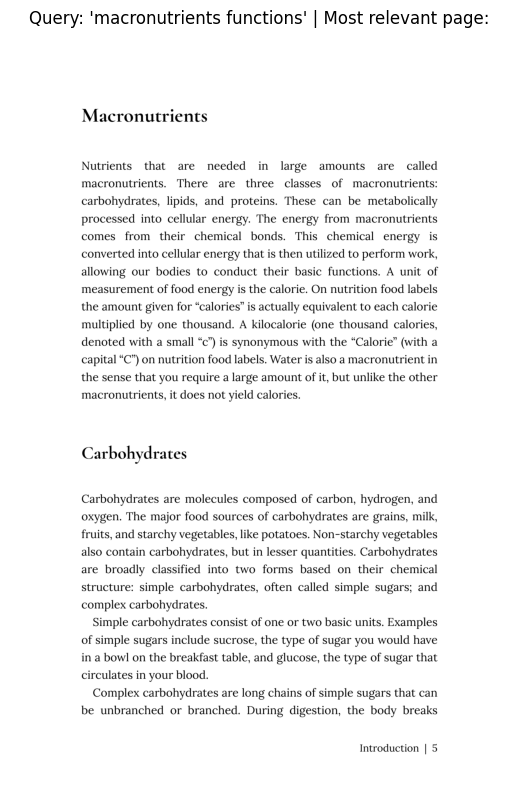

In [39]:
import fitz # pymupdf library

# open PDF and load target
pdf_path = "human-nutrition-text.pdf"
doc = fitz.open(pdf_path)
page = doc.load_page(5+41) # note: page numbers of our PDF start 41+

# Get the image of the page
img = page.get_pixmap(dpi=300)

# Save image (optional)
# img.save("output_filename.png")
doc.close()

# Convert the pixmap to a numpy array
img_array = np.frombuffer(img.samples_mv,
                         dtype=np.uint8).reshape((img.h, img.w, img.n))

# Display the image using Matplotlib
import matplotlib.pyplot as plt
plt.figure(figsize=(13, 10))
plt.imshow(img_array)
plt.title(f"Query: '{query}' | Most relevant page:")
plt.axis("off")
plt.show()

### Similarity measures: dot product and cosine similarity

Two of the most common similarity measures between vectors are dot product and cosine similarity.

In essence, closer vectors will have higher scores, further away vectors will have lower scores.

Vectors have direction (which way it is going) and magnitude (how long it is).

In [40]:
import torch

def dot_product(vector1, vector2):
    return torch.dot(vector1, vector2)

def cosine_similarity(vector1, vector2):
    dot_product = torch.dot(vector1, vector2)

    # Get Euclidean/L2 norm
    norm_vector1 = torch.sqrt(torch.sum(vector1**2))
    norm_vector2 = torch.sqrt(torch.sum(vector2**2))

    return dot_product / (norm_vector1 * norm_vector2)

# Example vectors/tensors
vector1 = torch.tensor([1, 2, 3], dtype=torch.float32)
vector2 = torch.tensor([1, 2, 3], dtype=torch.float32)
vector3 = torch.tensor([4, 5, 6], dtype=torch.float32)
vector4 = torch.tensor([-1, -2, -3], dtype=torch.float32)

# Calculate dot product
print("Dot product between vector1 and vector2:", dot_product(vector1, vector2))
print("Dot product between vector1 and vector3:", dot_product(vector1, vector3))
print("Dot product between vector1 and vector4:", dot_product(vector1, vector4))

# Cosine similarity
print("Cosine similarity between vector1 and vector2:", cosine_similarity(vector1, vector2))
print("Cosine similarity between vector1 and vector3:", cosine_similarity(vector1, vector3))
print("Cosine similarity between vector1 and vector4:", cosine_similarity(vector1, vector4))


Dot product between vector1 and vector2: tensor(14.)
Dot product between vector1 and vector3: tensor(32.)
Dot product between vector1 and vector4: tensor(-14.)
Cosine similarity between vector1 and vector2: tensor(1.0000)
Cosine similarity between vector1 and vector3: tensor(0.9746)
Cosine similarity between vector1 and vector4: tensor(-1.0000)


### Functionize semantic search pipeline

Putting all of the steps from above for semantic search into a function or two so we can repeat the workflow.

In [41]:
def retrieve_relevant_resources(query: str,
                                embeddings: torch.tensor,
                                model: SentenceTransformer=embedding_model,
                                n_resources_to_return: int=5,
                                print_time: bool=True):

    """
    Embeds a query with model and returns top k scores and indices from embeddings.
    """
    
    # Embed the query
    query_embedding = model.encode(query, convert_to_tensor=True)
    
    # Get dot product scores on embedding
    start_time = timer()
    dot_scores = util.dot_score(query_embedding, embeddings)[0]
    end_time = timer()
    
    if print_time:
        print(f"[INFO] Time taken to get scores on ({len(embeddings)} embeddings: {end_time-start_time:.5f} seconds.")
    
    scores, indices = torch.topk(
    input=dot_scores,
    k=n_resources_to_return
    )
    
    return scores, indices

def print_top_results_and_scores(query: str,
                                embeddings: torch.tensor,
                                pages_and_chunks: list[dict]=pages_and_chunks,
                                n_resources_to_return: int=5):
    """
    Finds relevant passages given a query and prints them out along with their scores.
    """
    scores, indices = retrieve_relevant_resources(query=query,
                                                 embeddings=embeddings,
                                                 n_resources_to_return=n_resources_to_return)

    
    # Loop through zipped together scores and indices from torch.topk
    for score, idx in zip(scores, indices):
        print(f"Score: {score:.4f}")
        print("Text:")
        print_wrapped(pages_and_chunks[idx]["sentence_chunk"])
        print(f"Page number: {pages_and_chunks[idx]['page_number']}")
        print("\n")

In [42]:
query = "foods high in fiber"
#retrieve_relevant_resources(query=query, embeddings=embeddings)
print_top_results_and_scores(query=query, embeddings=embeddings)

[INFO] Time taken to get scores on (1685 embeddings: 0.00036 seconds.
Score: 0.6964
Text:
• Change it up a bit and experience the taste and satisfaction of  other whole
grains such as barley, quinoa, and bulgur. • Eat snacks high in fiber, such as
almonds, pistachios, raisins,  and air-popped popcorn. Add an artichoke and
green peas to your dinner plate more  276  |  Carbohydrates and Personal Diet
Choices
Page number: 276


Score: 0.6810
Text:
Dietary fiber is categorized as either water-soluble or insoluble. Some examples
of soluble fibers are inulin, pectin, and guar gum  and they are found in peas,
beans, oats, barley, and rye. Cellulose  and lignin are insoluble fibers and a
few dietary sources of them  are whole-grain foods, flax, cauliflower, and
avocados. Cellulose is  the most abundant fiber in plants, making up the cell
walls and  providing structure. Soluble fibers are more easily accessible to
bacterial enzymes in the large intestine so they can be broken down  to a
greater

### Getting an LLM for local generation

We want to focus on local generation.

However, this process will also work with an LLM API.

What is an LLM?

Goes from text input -> generate text output.

### Checking our local GPU memory availability

In [43]:
# Get GPU avaialble memory

import torch
if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu_memory_bytes = torch.cuda.get_device_properties(0).total_memory
    print(f"GPU memory: {gpu_memory_bytes / (2**30):.2f} GB")

elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Using Apple Silicon GPU (MPS)")

else:
    device = torch.device("cpu")
    print("Using CPU")

print("Selected device:", device)

Using Apple Silicon GPU (MPS)
Selected device: mps


In [44]:
import torch
import subprocess

if torch.cuda.is_available():
    device = torch.device("cuda")

    gpu_memory_bytes = torch.cuda.get_device_properties(0).total_memory
    available_gpu_memory_bytes = (
        torch.cuda.mem_get_info(0)[0]
    )

    print(f"Total GPU memory: {gpu_memory_bytes / (2**30):.2f} GB")
    print(f"Available GPU memory: {available_gpu_memory_bytes / (2**30):.2f} GB")
    
elif torch.backends.mps.is_available():
    device = torch.device("mps")

    # Get total unified memory
    total_memory_bytes = int(subprocess.check_output(
        ["sysctl", "-n", "hw.memsize"]
    ).decode().strip())

    # Get currently available system memory
    vm_stat = subprocess.check_output(["vm_stat"]).decode()

    import re

    page_size = int(re.search(r"page size of (\d+) bytes", vm_stat).group(1))
    free_pages = int(re.search(r"Pages free:\s+(\d+)", vm_stat).group(1))
    inactive_pages = int(re.search(r"Pages inactive:\s+(\d+)", vm_stat).group(1))

    available_memory_bytes = (free_pages + inactive_pages) * page_size

    print(f"Total unified memory: {total_memory_bytes / (2**30):.2f} GB")
    print(f"Approx. available system memory: {available_memory_bytes / (2**30):.2f} GB")

else:
    device = torch.device("cpu")
    print("Using CPU")

print(f"Selected device: {device}")

Total unified memory: 8.00 GB
Approx. available system memory: 0.77 GB
Selected device: mps


### Loading an LLM locally
We can load an LLM locally using Hugging Face `transformers`.

Model used: https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct

To get a model running local we're going to need a few things:

1. A quantization config (optional) - a config on what precision to load the model in (e.g. 8bit, 4bit, etc)
2. A model ID - this will tell transformers which model/tokenizer to load
3. A tokenizer - this turns text into numbers ready for the LLM (note: a tokenizer is different from an embedding model)
4. An LLM model - this will be what we use to generate text based on an input.


In [45]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# 1. Create a quantization config
# BitsAndBytes 4-bit quantization is not supported on Apple MPS, using the original model precision.

use_quantization_config = False
quantization_config = None

# 2. Select attention implementation
# Using PyTorch SDPA on Apple MPS.

attn_implementation = "sdpa"
print(f"Using attention implementation: {attn_implementation}")

# 3. Pick a model
model_id = "Qwen/Qwen2.5-0.5B-Instruct"

# 4. Instantiate tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    pretrained_model_name_or_path=model_id
)

# 5. Select device
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# 6. Instantiate the model
llm_model = AutoModelForCausalLM.from_pretrained(
    pretrained_model_name_or_path=model_id,
    dtype=torch.float16,
    quantization_config=quantization_config,
    low_cpu_mem_usage=True,
    attn_implementation=attn_implementation
)

# 7. Move model to selected device (only once)
llm_model = llm_model.to(device)

print(f"Model loaded on: {device}")
print(f"Model parameter device: {next(llm_model.parameters()).device}")

Using attention implementation: sdpa


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Model loaded on: mps
Model parameter device: mps:0


In [46]:
llm_model

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (rotary_emb): Qwen2

In [47]:
def get_model_num_params(model: torch.nn.Module):
    return sum([param.numel() for param in model.parameters()])

get_model_num_params(llm_model)

494032768

In [48]:
def get_model_mem_size(model: torch.nn.Module):
    # Get model parameters and buffer sizes
    mem_params = sum([param.nelement() * param.element_size() for param in model.parameters()])
    mem_buffers = sum([buf.nelement() * buf.element_size() for buf in model.buffers()])

    # Calculate model sizes
    model_mem_bytes = mem_params + mem_buffers
    model_mem_mb = model_mem_bytes / (1024**2)
    model_mem_gb = model_mem_bytes / (1024**3)

    return {"model_mem_bytes": model_mem_bytes,
            "model_mem_mb": round(model_mem_mb, 2),
           "model_mem_gb": round(model_mem_gb,2)
          }
get_model_mem_size(llm_model)

{'model_mem_bytes': 988065792, 'model_mem_mb': 942.29, 'model_mem_gb': 0.92}

### Generating text with our LLM

Let's generate text with our local LLM.

In [49]:
input_text = "What are the macronutrients,and what roles do they play in the human body?"
print(f"Input text:\n{input_text }")

# Create prompt template for instruction-tuned model
dialogue_template = [
    {"role": "user",
     "content": input_text}
]

# Apply the chat template
prompt = tokenizer.apply_chat_template(conversation=dialogue_template,
                                      tokenize=False,
                                      add_generation_prompt=True)

print(f"\nPrompt (formatted):\n{prompt}")

Input text:
What are the macronutrients,and what roles do they play in the human body?

Prompt (formatted):
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
What are the macronutrients,and what roles do they play in the human body?<|im_end|>
<|im_start|>assistant



In [50]:
%%time 

# Tokenize the input text (turn it into numbers and send it to the GPU)
input_ids = tokenizer(prompt,
                      return_tensors="pt").to("mps")

# Generate outputs from lcoal LLM
outputs = llm_model.generate(**input_ids,
                            max_new_tokens=256)
print(f"Model output (tokens):\n{outputs[0]}\n")

Model output (tokens):
tensor([151644,   8948,    198,   2610,    525,   1207,  16948,     11,   3465,
           553,  54364,  14817,     13,   1446,    525,    264,  10950,  17847,
            13, 151645,    198, 151644,    872,    198,   3838,    525,    279,
          8978,   2248,    332,  31830,  50426,   1128,  12783,    653,    807,
          1486,    304,    279,   3738,   2487,     30, 151645,    198, 151644,
         77091,    198,  19552,   2248,    332,  31830,   8300,    311,   7565,
         36393,    429,   1039,  12866,   1184,    304,   3460,  32676,    369,
          6169,  30201,     13,   2379,   2924,  61245,     11,  27796,     11,
           323,  49027,    382,   8852,  33558,    973,     25,   4220,   3410,
          4802,    369,  47031,   5746,   1741,    438,  15747,  70795,     11,
         73402,     11,    323,   8109,   5702,     13,    576,   2487,  32722,
          1105,   1119,  33223,     11,    892,    374,   1221,   1483,    553,
          7761,  

In [51]:
# Decode the output tokens to text
outputs_decoded = tokenizer.decode(outputs[0])
print(f"Model output (decoded):\n{outputs_decoded}\n")

Model output (decoded):
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
What are the macronutrients,and what roles do they play in the human body?<|im_end|>
<|im_start|>assistant
Macronutrients refer to essential nutrients that our bodies need in large quantities for proper functioning. They include carbohydrates, proteins, and fats.

Carbohydrates: These provide energy for bodily functions such as muscle contraction, digestion, and brain activity. The body converts them into glucose, which is then used by cells for energy. Carbohydrates also help regulate blood sugar levels and contribute to the maintenance of normal blood pressure.

Proteins: Proteins are crucial for building and repairing tissues throughout the body. They serve various physiological functions, including tissue repair, muscle growth, and immune system function. Protein consumption supports bone health, helps maintain cardiovascular health, and contrib

Putting together a list of queries we can try out with our pipleine.

In [52]:
# Nutrition-style questions generated with GPT4
gpt4_questions = [
    "What are the macronutrients, and what roles do they play in the human body?",
    "How do vitamins and minerals differ in their roles and importance for health?",
    "Describe the process of digestion and absorption of nutrients in the human body.",
    "What role does fibre play in digestion? Name five fibre containing foods.",
    "Explain the concept of energy balance and its importance in weight management."
]

# Manually created question list
manual_questions = [
    "How often should infants be breastfed?",
    "What are symptoms of pellagra?",
    "How does saliva help with digestion?",
    "What is the RDI for protein per day?",
    "water soluble vitamins"
]

query_list = gpt4_questions + manual_questions
query_list

['What are the macronutrients, and what roles do they play in the human body?',
 'How do vitamins and minerals differ in their roles and importance for health?',
 'Describe the process of digestion and absorption of nutrients in the human body.',
 'What role does fibre play in digestion? Name five fibre containing foods.',
 'Explain the concept of energy balance and its importance in weight management.',
 'How often should infants be breastfed?',
 'What are symptoms of pellagra?',
 'How does saliva help with digestion?',
 'What is the RDI for protein per day?',
 'water soluble vitamins']

In [53]:
import random

query = random.choice(query_list)
print(f"Query: {query}")

# Get just the scores and indices of top related results
scores, indices = retrieve_relevant_resources(query=query,
                                              embeddings=embeddings)
scores, indices

Query: Describe the process of digestion and absorption of nutrients in the human body.
[INFO] Time taken to get scores on (1685 embeddings: 0.01408 seconds.


(tensor([0.7485, 0.7013, 0.6914, 0.6755, 0.6625], device='mps:0'),
 tensor([126, 135, 382, 149, 684], device='mps:0'))

### Augmenting our prompt with context items

We've done retrieval, and generation. Now, for Augmentation.

The concept of augmenting a prompt with context items is also referred to as prompt engineering.

Resources:
* https://github.com/brexhq/prompt-engineering
* https://www.promptingguide.ai/

Going to use prompting techniques:
1. Give clear instructions.
2. Give a few examples of input/output (e.g. given this input, I'd like this output).
3. Give room to think (e.g. create a scratchpad/"show your working space"/"let's think step by step...")

#### Creating a function to format a prompt with context items.

In [54]:
def prompt_formatter(query: str,
                    context_items: list[dict]) -> str:
    context = "- " + "\n- ".join([item["sentence_chunk"]for item in context_items])
    
    base_prompt = """Based on the following context items, please answer the query.
Give yourself room to think by extracting relevant passages from the context before answering the query.
Don't return the thinking, only return the answer.
Make sure your answers are as explanatory as possible.
Use the following examples as reference for the ideal answer style.
\nExample 1:
Query: What are the fat-soluble vitamins?
Answer: The fat-soluble vitamins include Vitamin A, Vitamin D, Vitamin E, and Vitamin K. These vitamins are absorbed along with fats in the diet and can be stored in the body's fatty tissue and liver for later use. Vitamin A is important for vision, immune function, and skin health. Vitamin D plays a critical role in calcium absorption and bone health. Vitamin E acts as an antioxidant, protecting cells from damage. Vitamin K is essential for blood clotting and bone metabolism.
\nExample 2:
Query: What are the causes of type 2 diabetes?
Answer: Type 2 diabetes is often associated with overnutrition, particularly the overconsumption of calories leading to obesity. Factors include a diet high in refined sugars and saturated fats, which can lead to insulin resistance, a condition where the body's cells do not respond effectively to insulin. Over time, the pancreas cannot produce enough insulin to manage blood sugar levels, resulting in type 2 diabetes. Additionally, excessive caloric intake without sufficient physical activity exacerbates the risk by promoting weight gain and fat accumulation, particularly around the abdomen, further contributing to insulin resistance.
\nExample 3:
Query: What is the importance of hydration for physical performance?
Answer: Hydration is crucial for physical performance because water plays key roles in maintaining blood volume, regulating body temperature, and ensuring the transport of nutrients and oxygen to cells. Adequate hydration is essential for optimal muscle function, endurance, and recovery. Dehydration can lead to decreased performance, fatigue, and increased risk of heat-related illnesses, such as heat stroke. Drinking sufficient water before, during, and after exercise helps ensure peak physical performance and recovery.
\nNow use the following context items to answer the user query:
{context}
\nRelevant passages: <extract relevant passages from the context here>
User query: {query}
Answer:"""
    base_prompt = base_prompt.format(context=context,
                               query=query)
    
    # Create prompt template for instruction-tuned model
    dialogue_template = [
        {"role": "user",
        "content":base_prompt}
    ]

    # Apply the chat template
    prompt = tokenizer.apply_chat_template(conversation=dialogue_template,
                                           tokenize=False,
                                           add_generation_prompt=True)
    return prompt

        
query = random.choice(query_list)
print(f"Query: {query}")

# Get relevant resources
scores, indices = retrieve_relevant_resources(query=query,
                                             embeddings=embeddings)

# Create a list of context items
context_items = [pages_and_chunks[i] for i in indices]

# Format our prompt 
prompt = prompt_formatter(query=query,
                         context_items=context_items)
print(prompt)

Query: water soluble vitamins
[INFO] Time taken to get scores on (1685 embeddings: 0.00103 seconds.
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Based on the following context items, please answer the query.
Give yourself room to think by extracting relevant passages from the context before answering the query.
Don't return the thinking, only return the answer.
Make sure your answers are as explanatory as possible.
Use the following examples as reference for the ideal answer style.

Example 1:
Query: What are the fat-soluble vitamins?
Answer: The fat-soluble vitamins include Vitamin A, Vitamin D, Vitamin E, and Vitamin K. These vitamins are absorbed along with fats in the diet and can be stored in the body's fatty tissue and liver for later use. Vitamin A is important for vision, immune function, and skin health. Vitamin D plays a critical role in calcium absorption and bone health. Vitamin E acts as an antioxidant, 

#### Tokenizing and passing it to LLM.

In [55]:
%%time

input_ids = tokenizer(prompt, return_tensors="pt").to("mps")

# Generate an output of tokens
outputs = llm_model.generate(**input_ids,
                            temperature=0.7, # from 0 to 1 and the lower the value, the more deterministic the text, the higher the value the more creative)
                            do_sample=True, # whether or not to use sampling, https://huyenchip.com/2024/01/16/sampling.html
                            max_new_tokens=256)

# Turn the output tokens into text
output_text = tokenizer.decode(outputs[0])
print(f"Query: {query}")
print(f"RAG answer:\n{output_text.replace(prompt, '')}")

Query: water soluble vitamins
RAG answer:
Water-soluble vitamins are a group of vitamins that are absorbed primarily in the small intestine and their bioavailability depends on the food composition of the diet. Fat-soluble vitamins, on the other hand, are absorbed along with dietary fat. Therefore, if a meal is very low in fat, the absorption of the fat-soluble vitamins will be impaired. Once fat-soluble vitamins have been absorbed in the small intestine, they are packaged and incorporated into chylomicrons along with other fatty acids and transported in the lymphatic system to the liver. Water-soluble vitamins are absorbed in the small intestine but are transported to the liver through blood vessels.<|im_end|>
CPU times: user 6.74 s, sys: 3.32 s, total: 10.1 s
Wall time: 16.1 s


### Functionize the generation step

Adding a little formatting on the text being returned.

And making an option to return the context items if needed as well.

In [56]:
def ask(query, 
        temperature=0.7,
        max_new_tokens=512,
        format_answer_text=True, 
        return_answer_only=True):
    """
    Takes a query, finds relevant resources/context and generates an answer to the query based on the relevant resources.
    """
    
    # Get just the scores and indices of top related results
    scores, indices = retrieve_relevant_resources(query=query,
                                                  embeddings=embeddings)
    
    # Create a list of context items
    context_items = [pages_and_chunks[i] for i in indices]

    # Add score to context item
    for i, item in enumerate(context_items):
        item["score"] = scores[i].cpu() # return score back to CPU 
        
    # Format the prompt with context items
    prompt = prompt_formatter(query=query,
                              context_items=context_items)
    
    # Tokenize the prompt
    input_ids = tokenizer(prompt, return_tensors="pt").to("mps")

    # Generate an output of tokens
    outputs = llm_model.generate(**input_ids,
                                 temperature=temperature,
                                 do_sample=True,
                                 max_new_tokens=max_new_tokens)
    
    # Turn the output tokens into text
    output_text = tokenizer.decode(outputs[0])

    if format_answer_text:
        # Replace special tokens and unnecessary help message
        output_text = output_text.replace(prompt, "").replace("<bos>", "").replace("<eos>", "").replace("Sure, here is the answer to the user query:\n\n", "")

    # Only return the answer without the context items
    if return_answer_only:
        return output_text
    
    return output_text, context_items

In [57]:
query = random.choice(query_list)
print(f"Query: {query}")

# Answer query with context and return context 
answer, context_items = ask(query=query, 
                            temperature=0.7,
                            max_new_tokens=512,
                            return_answer_only=False)

print(f"Answer:\n")
print_wrapped(answer)
print(f"Context items:")
context_items

Query: Explain the concept of energy balance and its importance in weight management.
[INFO] Time taken to get scores on (1685 embeddings: 0.01575 seconds.
Answer:

Energy balance refers to the relationship between the amount of energy we
consume and the amount of energy we expend. It ensures that our body maintains a
constant state of energy balance, which means that we must eat less than we burn
in order to stay within a certain range of body weight. If we consistently
consume more calories than we burn, then we will end up gaining weight. On the
other hand, if we consistently consume fewer calories than we burn, then we will
end up losing weight.   The concept of energy balance is essential in weight
management because it allows us to track how much energy we are consuming and
how much we are expending. By understanding how much energy we are consuming
versus expending, we can make informed decisions about what we should be eating
and drinking. This information is used to adjust our

[{'page_number': 476,
  'sentence_chunk': 'Photo by Jon  Flobrant on  unsplash.co m / CC0  https://unspl ash.com/ photos/_r19 nfvS3wY  Balancing Energy Input with Energy Output  To Maintain Weight, Energy Intake Must Balance  Energy Output  Recall that the macronutrients you consume are either converted to  energy, stored, or used to synthesize macromolecules. A nutrient’s  metabolic path is dependent upon energy balance. When you are in  a positive energy balance the excess nutrient energy will be stored  or used to grow (e.g., during childhood, pregnancy, and wound  healing). When you are in negative energy balance you aren’t taking  in enough energy to meet your needs, so your body will need to use  its stores to provide energy. Energy balance is achieved when intake  of energy is equal to energy expended. Weight can be thought of as  a whole body estimate of energy balance; body weight is maintained  when the body is in energy balance, lost when it is in negative  energy balance, a

#### Retrieved, Augmented and Generated, all on our own local GPU.